# DO Early-Warning System: End-to-End Training, Ensemble Learning and Blind Evaluation

### Forecasting low dissolved oxygen 24 hours ahead in 30 US rivers from multimodal environmental data
**21CSC305P Machine Learning, SRM Institute of Science and Technology, Ramapuram**

This notebook builds the complete forecasting system from raw processed data: it audits the chronological
split, fits every preprocessing step on 2023 alone, trains five learners from two model families, combines them
into the two final ensembles on the 2024 tuning year, and only then evaluates on the blind 2025 test year.

**What is trained here.** Three machine-learning models, Random Forest, XGBoost and LightGBM, and two
multi-task deep networks, BiLSTM and CNN-LSTM, trained on the GPU with mixed precision and early stopping.
Section 8 then fits the two ensembles: a **Ridge stacking meta-learner** for regression and **Caruana greedy
ensemble selection with replacement** for classification, the algorithm that produces the project's
`ensemble_v21`. Both are fitted on 2024 only.

**Reported metrics.** Five per task, the same five the evaluation notebook reports: R2, RMSE, MAE, NSE and
Skill vs persistence for regression; Accuracy, macro Precision, macro Recall, macro F1 and macro one-vs-rest
ROC-AUC for classification. Classification always uses the plain `argmax` rule; the operational warning rule
`P(Low) >= tau` is fitted in Section 8.1 but is never used for the metric tables.

> **Runs in a few minutes.** Training uses the **demo pack**: the project's real processed data for all 30
> stations, thinned to every 4th hour, about 64,000 rows per year. With `FAST_DEMO = True` the Random Forest
> uses 100 trees instead of 300 and the networks stop after at most 10 epochs; every other hyperparameter is
> the frozen one. Section 10 places these demo numbers next to the official full-dataset results.

## 0. Data Pack

The notebook needs one file, `do_demo_pack.npz` (about 77 MB, produced by `python make_demo_pack.py`). It
carries the hourly channel history for all 30 stations, the 211 engineered features for the three split years,
and the regression and classification targets at the four horizons.

Put it in the top folder of Google Drive, or let the cell prompt for an upload; on a local machine it is read
from the project folder. `FAST_DEMO` controls the size of the run and nothing else about the method.

In [1]:
# @title 0. Locate and load do_demo_pack.npz
import os, sys, numpy as np
PACK = None
for p in ["do_demo_pack.npz", "../do_demo_pack.npz", "/content/do_demo_pack.npz", "/content/drive/MyDrive/do_demo_pack.npz"]:
    if os.path.exists(p):
        PACK = p; break
if PACK is None and "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    if os.path.exists("/content/drive/MyDrive/do_demo_pack.npz"):
        PACK = "/content/drive/MyDrive/do_demo_pack.npz"
    else:
        from google.colab import files
        print("do_demo_pack.npz is not in My Drive - please upload it now:")
        files.upload(); PACK = "do_demo_pack.npz"
assert PACK and os.path.exists(PACK), "do_demo_pack.npz not found"
D = dict(np.load(PACK))
FAST_DEMO = True   # True: 100 RF trees, <= 10 epochs (about 5 min on a Colab T4) | False: frozen 300 trees, <= 15 epochs
print(f"[OK] loaded {PACK} ({os.path.getsize(PACK) / 1e6:.0f} MB): {len(D['stations'])} stations, "
      f"{len(D['feature_names'])} features, {D['channels'].shape[0]:,} station-hours of raw history")

[OK] loaded ../do_demo_pack.npz (77 MB): 30 stations, 211 features, 789,120 station-hours of raw history


## 1. Runtime Environment and GPU

The two deep networks train on the GPU with automatic mixed precision, so the cell below records exactly which
hardware and library versions produced the numbers in this notebook. Every random seed is fixed here, which is
what makes a rerun on the same hardware reproduce the same results.

In [2]:
# @title 1. Environment and GPU check
import time, random, warnings, json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
import sklearn, xgboost as xgb, lightgbm as lgb
import torch, torch.nn as nn
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
TIMES = {}

print("=" * 80)
print("DO EARLY-WARNING SYSTEM: TRAINING RUNTIME ENVIRONMENT")
print(f"Python           : {sys.version.split()[0]}")
print(f"scikit-learn     : {sklearn.__version__} | XGBoost {xgb.__version__} | LightGBM {lgb.__version__}")
print(f"PyTorch          : {torch.__version__}")
print(f"Hardware Compute : {device}")
if device.type == "cuda":
    print(f"GPU Device Name  : {torch.cuda.get_device_name(0)}")
    print(f"Total VRAM       : {torch.cuda.get_device_properties(0).total_memory / 1024**2:,.0f} MB")
else:
    print("No GPU found - deep models train on the CPU (slower). In Colab: Runtime -> Change runtime type -> T4 GPU")
print(f"CPU cores        : {os.cpu_count()}")
print("=" * 80)

DO EARLY-WARNING SYSTEM: TRAINING RUNTIME ENVIRONMENT
Python           : 3.10.8
scikit-learn     : 1.4.2 | XGBoost 2.0.3 | LightGBM 4.3.0
PyTorch          : 2.2.2+cu121
Hardware Compute : cuda
GPU Device Name  : NVIDIA GeForce RTX 3050 6GB Laptop GPU
Total VRAM       : 6,144 MB
CPU cores        : 16


## 2. Dataset Audit and Leakage Verification

Neighbouring hours in a river series are near-duplicates. A random split would put 10:00 in training and 11:00
in testing, letting a model answer from memory and inflating every score. The split is therefore
**chronological by calendar year**: fit on 2023, tune on 2024, test blind on 2025.

The cell below prints the class balance of each split and asserts the ordering holds with no overlap, so the
leakage claim is checked rather than asserted in prose.

In [3]:
# @title 2. Partition audit and leakage verification
FEATURES = list(D["feature_names"]); TARGETS = list(D["target_names"]); STATIONS = list(D["stations"])
H_ALL = [6, 12, 24, 48]; H = 24                          # this notebook reports the 24 h horizon
CLASSES = ["Low", "Medium", "Good"]; LOW, GOOD = 5.0, 7.0
col = {t: i for i, t in enumerate(TARGETS)}

def to_class(do):
    out = np.full(do.shape, np.nan); out[do < LOW] = 0; out[(do >= LOW) & (do <= GOOD)] = 1; out[do > GOOD] = 2
    return out

SPLITS = {}
for s, year in [("train", 2023), ("val", 2024), ("test", 2025)]:
    SPLITS[s] = {"X": pd.DataFrame(D[f"{s}_X"], columns=FEATURES), "y": D[f"{s}_y"], "do_now": D[f"{s}_do_now"].astype("float64"),
                 "station": D[f"{s}_station"].astype(int), "pos": D[f"{s}_pos"].astype(int), "time": D[f"{s}_time"]}
    SPLITS[s]["class_now"] = to_class(SPLITS[s]["do_now"])

rows = []
for s, d in SPLITS.items():
    c = d["y"][:, col[f"y_cls_{H}"]]
    rows.append({"split": s, "rows": len(d["X"]), "stations": len(np.unique(d["station"])),
                 "from": str(d["time"].min())[:10], "to": str(d["time"].max())[:10],
                 "% Low": np.nanmean(c == 0) * 100, "% Medium": np.nanmean(c == 1) * 100, "% Good": np.nanmean(c == 2) * 100})
display(pd.DataFrame(rows).set_index("split").style.format("{:.1f}", subset=["% Low", "% Medium", "% Good"]))

ok_order = SPLITS["train"]["time"].max() < SPLITS["val"]["time"].min() and SPLITS["val"]["time"].max() < SPLITS["test"]["time"].min()
print("=" * 80)
print("LEAKAGE VERIFICATION:")
print(f"  last training hour   : {SPLITS['train']['time'].max()}")
print(f"  first validation hour: {SPLITS['val']['time'].min()}   last: {SPLITS['val']['time'].max()}")
print(f"  first test hour      : {SPLITS['test']['time'].min()}")
print(f"  chronological order  : {'PASSED [OK]' if ok_order else 'FAILED'}  (train < validation < test, no overlap)")
print(f"  features use only data at or before time t; targets are DO at t+{H} h")
print("=" * 80)

,rows,stations,from,to,% Low,% Medium,% Good
split,,,,,,,
train,63818,30,2023-01-04,2023-12-29,19.1,27.4,52.8
val,63408,30,2024-01-01,2024-12-29,20.3,24.3,54.7
test,63497,30,2025-01-01,2025-12-31,19.4,24.9,54.8


LEAKAGE VERIFICATION:
  last training hour   : 2023-12-29T23
  first validation hour: 2024-01-01T00   last: 2024-12-29T23
  first test hour      : 2025-01-01T00
  chronological order  : PASSED [OK]  (train < validation < test, no overlap)
  features use only data at or before time t; targets are DO at t+24 h


## 3. Preprocessing, Class Imbalance and the Metric Set

Every statistic a model depends on is estimated on 2023 only: the median imputer for the Random Forest, the
scalers for the deep networks and the class weights. The boosting libraries learn their own direction for
missing values, so they are given the raw features untouched.

| Step | What | Fitted on |
|---|---|---|
| Missing values (trees) | XGBoost and LightGBM learn a direction for NaN; Random Forest uses a median imputer | 2023 only |
| Missing values (deep) | raw series forward-filled within a station, never backwards; remaining gaps = training median | 2023 only |
| Scaling (deep) | `StandardScaler` on the 33 hourly channels and on the 211 features | 2023 only |
| Class imbalance | weights $w_c = n / (K \cdot n_c)$, so the minority **Low** band counts as much as the others | 2023 only |

This cell also defines the single `evaluate` function used everywhere below, which returns exactly the ten
reported metrics, and the `summarise` helper that prints one clean block per model.

In [4]:
# @title 3. Targets, class weights, the ten reported metrics and the per-model summary
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score, precision_score,
                             roc_auc_score, confusion_matrix, roc_curve, auc as sk_auc)

REG_KEYS = ["R2", "RMSE", "MAE", "NSE", "Skill vs persistence"]
CLS_KEYS = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "ROC-AUC (macro OvR)"]
ALL_KEYS = REG_KEYS + CLS_KEYS


def xy(split, task):
    d = SPLITS[split]; y = d["y"][:, col[f"y_{'reg' if task == 'regression' else 'cls'}_{H}"]].astype("float64")
    ok = ~np.isnan(y)
    return d["X"][ok], (y[ok] if task == "regression" else y[ok].astype(int))


def balanced_weights(y):
    cls, cnt = np.unique(y, return_counts=True); w = {c: len(y) / (len(cls) * n) for c, n in zip(cls, cnt)}
    return np.array([w[v] for v in y])


def early_warning(class_now, y_true, y_pred):
    """Onset recall and false-alarm rate: used only to fit the warning threshold in Section 8.1."""
    ok = ~np.isnan(class_now) & ~np.isnan(y_true)
    now, t, p = class_now[ok], y_true[ok], y_pred[ok]
    onset = (now != 0) & (t == 0); safe = (now != 0) & (t != 0)
    return {"onset_recall": (onset & (p == 0)).sum() / max(onset.sum(), 1),
            "false_alarm": (safe & (p == 0)).sum() / max(safe.sum(), 1)}


def evaluate(split, reg, proba, pred=None):
    """
    The ten reported metrics on one split, at the 24 h horizon.

    Regression: R2 and NSE are both 1 - SSE/SST against the observed mean, so they agree by construction;
    both are reported because the hydrology literature expects NSE. Skill vs persistence is the fractional
    RMSE reduction against the no-change forecast on the same rows.
    Classification: the argmax rule unless an explicit `pred` is supplied.
    """
    d = SPLITS[split]
    yr = d["y"][:, col[f"y_reg_{H}"]].astype("float64")
    yc = d["y"][:, col[f"y_cls_{H}"]].astype("float64")
    out = {}
    if reg is not None:
        ok_r = ~np.isnan(yr) & ~np.isnan(reg)
        e = reg[ok_r] - yr[ok_r]
        sse, sst = float(np.sum(e ** 2)), float(np.sum((yr[ok_r] - yr[ok_r].mean()) ** 2))
        rmse = float(np.sqrt(np.mean(e ** 2)))
        pers = float(np.sqrt(np.mean((d["do_now"][ok_r] - yr[ok_r]) ** 2)))
        out.update({"R2": 1 - sse / sst, "RMSE": rmse, "MAE": float(np.mean(np.abs(e))),
                    "NSE": 1 - sse / sst, "Skill vs persistence": 1 - rmse / pers})
    if proba is not None:
        pred = proba.argmax(1) if pred is None else pred
        ok = ~np.isnan(yc) & ~np.isnan(proba).any(1)
        t, p = yc[ok].astype(int), np.asarray(pred)[ok].astype(int)
        degenerate = np.allclose(proba[ok].max(1), 1.0)      # one-hot (persistence): no ranking to score
        out.update({"Accuracy": accuracy_score(t, p),
                    "Precision (macro)": precision_score(t, p, average="macro", zero_division=0),
                    "Recall (macro)": recall_score(t, p, average="macro", zero_division=0),
                    "F1 (macro)": f1_score(t, p, average="macro"),
                    "ROC-AUC (macro OvR)": (np.nan if degenerate else
                                            roc_auc_score(t, proba[ok], multi_class="ovr", average="macro"))})
    return out


def summarise(title, split, reg, proba, seconds=None, pred=None, note=""):
    """One clean block per model: training time, then the five regression and five classification metrics."""
    m = evaluate(split, reg, proba, pred)
    bar = "-" * 78
    print(bar)
    head = f"{title}  |  {split} split ({2024 if split == 'val' else 2025}), {H} h ahead"
    if seconds is not None:
        head += f"  |  trained in {seconds:,.1f} s"
    print(head)
    if note:
        print(f"  note: {note}")
    print(f"  regression     " + "  ".join(f"{k} {m[k]:.4f}" for k in REG_KEYS if k in m))
    print(f"  classification " + "  ".join(f"{k} {m[k]:.4f}" for k in CLS_KEYS if k in m))
    print(bar)
    return m


PRED = {}          # PRED[model] = {"val_reg", "val_proba", "test_reg", "test_proba"}
VAL_SUMMARY = {}   # VAL_SUMMARY[model] = the ten metrics on 2024, filled in as each model finishes
_, ytr = xy("train", "classification")
print("Class counts in 2023 (24 h target):", dict(zip(CLASSES, np.bincount(ytr))))
print("Balanced class weights            :", {CLASSES[c]: round(len(ytr) / (3 * n), 3)
                                               for c, n in enumerate(np.bincount(ytr))})
print(f"\nReported metrics, regression     : {REG_KEYS}")
print(f"Reported metrics, classification : {CLS_KEYS}  (argmax rule)")

Class counts in 2023 (24 h target): {'Low': 12173, 'Medium': 17497, 'Good': 33693}
Balanced class weights            : {'Low': 1.735, 'Medium': 1.207, 'Good': 0.627}

Reported metrics, regression     : ['R2', 'RMSE', 'MAE', 'NSE', 'Skill vs persistence']
Reported metrics, classification : ['Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)', 'ROC-AUC (macro OvR)']  (argmax rule)


## 4. Model 1 of 5: Random Forest

A bagged ensemble of decision trees: each tree sees a bootstrap half of the rows and 30 % of the features at
every split, and the forecast is their average. It is the project's variance-reduction baseline and the only
tree model here that needs an explicit imputer.

$$\hat y(x) = \frac{1}{T}\sum_{t=1}^{T} f_t(x)$$

Frozen settings: 300 trees (100 with `FAST_DEMO`), `min_samples_leaf=20`, `max_features=0.3`,
`max_samples=0.5`, `class_weight="balanced_subsample"`, median imputer fitted on 2023.

In [5]:
# @title 4. Train Random Forest (regression and classification)
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

RF = dict(n_estimators=100 if FAST_DEMO else 300, min_samples_leaf=20, max_features=0.3, max_samples=0.5, n_jobs=-1, random_state=SEED)
out, t0 = {}, time.perf_counter()
for task in ["regression", "classification"]:
    X, y = xy("train", task)
    est = RandomForestRegressor(**RF) if task == "regression" else RandomForestClassifier(class_weight="balanced_subsample", **RF)
    t1 = time.perf_counter(); model = Pipeline([("impute", SimpleImputer(strategy="median")), ("model", est)]).fit(X, y)
    print(f"  {task:<14} trained on {len(X):,} rows in {time.perf_counter() - t1:5.1f}s")
    for s in ["val", "test"]:
        Xs = SPLITS[s]["X"]
        out[f"{s}_{'reg' if task == 'regression' else 'proba'}"] = model.predict(Xs) if task == "regression" else model.predict_proba(Xs)
    if task == "regression":
        RF_IMP = pd.Series(model.named_steps["model"].feature_importances_, index=FEATURES)
PRED["random_forest"] = out; TIMES["Random Forest"] = time.perf_counter() - t0
VAL_SUMMARY["random_forest"] = summarise("4.  Random Forest", "val", out["val_reg"], out["val_proba"],
                                         seconds=TIMES["Random Forest"])

  regression     trained on 63,363 rows in  24.1s


  classification trained on 63,363 rows in  21.1s


------------------------------------------------------------------------------
4.  Random Forest  |  val split (2024), 24 h ahead  |  trained in 46.7 s
  regression     R2 0.9475  RMSE 0.6724  MAE 0.4160  NSE 0.9475  Skill vs persistence 0.0847
  classification Accuracy 0.9068  Precision (macro) 0.8859  Recall (macro) 0.8959  F1 (macro) 0.8906  ROC-AUC (macro OvR) 0.9807
------------------------------------------------------------------------------


## 5. Model 2 of 5: XGBoost

Second-order gradient boosting. Each new tree minimises a second-order expansion of the loss,
$\mathcal{L}^{(t)} \approx \sum_i [g_i f_t(x_i) + \tfrac12 h_i f_t(x_i)^2] + \gamma T + \tfrac12\lambda\lVert w\rVert^2$,
so it corrects the residuals of everything built before it rather than averaging independent trees.

Frozen settings: learning rate 0.05, depth 8, subsample 0.8, colsample 0.7, histogram splits on the GPU when
one is available, balanced sample weights, and **early stopping on 2024** with 50 rounds of patience and at
most 2,000 trees, so the tuning year chooses the model size.

In [6]:
# @title 5. Train XGBoost (GPU if available)
XG = dict(tree_method="hist", learning_rate=0.05, max_depth=8, subsample=0.8, colsample_bytree=0.7,
          n_estimators=2000, early_stopping_rounds=50, random_state=SEED, n_jobs=-1)
if device.type == "cuda":
    XG["device"] = "cuda"
out, CURVES, t0 = {}, {}, time.perf_counter()
for task in ["regression", "classification"]:
    X, y = xy("train", task); Xv, yv = xy("val", task)
    if task == "regression":
        model = xgb.XGBRegressor(eval_metric="rmse", **XG); w = None
    else:
        model = xgb.XGBClassifier(objective="multi:softprob", num_class=3, eval_metric="mlogloss", **XG); w = balanced_weights(y)
    t1 = time.perf_counter(); model.fit(X, y, sample_weight=w, eval_set=[(X, y), (Xv, yv)], verbose=False)
    CURVES[("XGBoost", task)] = model.evals_result()
    print(f"  {task:<14} best iteration {model.best_iteration:>4} | {time.perf_counter() - t1:5.1f}s")
    for s in ["val", "test"]:
        Xs = SPLITS[s]["X"]
        out[f"{s}_{'reg' if task == 'regression' else 'proba'}"] = model.predict(Xs) if task == "regression" else model.predict_proba(Xs)
PRED["xgboost"] = out; TIMES["XGBoost"] = time.perf_counter() - t0
VAL_SUMMARY["xgboost"] = summarise("5.  XGBoost", "val", out["val_reg"], out["val_proba"],
                                   seconds=TIMES["XGBoost"])

  regression     best iteration  202 |  12.8s


  classification best iteration  202 |  25.6s


------------------------------------------------------------------------------
5.  XGBoost  |  val split (2024), 24 h ahead  |  trained in 42.5 s
  regression     R2 0.9482  RMSE 0.6676  MAE 0.4142  NSE 0.9482  Skill vs persistence 0.0912
  classification Accuracy 0.9086  Precision (macro) 0.8886  Recall (macro) 0.8975  F1 (macro) 0.8927  ROC-AUC (macro OvR) 0.9816
------------------------------------------------------------------------------


## 6. Model 3 of 5: LightGBM

Leaf-wise boosting: instead of growing level by level, it splits the leaf with the largest loss reduction,
which reaches a lower training error for the same number of leaves. It is the strongest individual model in
this project on both tasks.

Frozen settings: learning rate 0.05, 63 leaves, at least 50 rows per leaf, 70 % feature and 80 % row bagging,
`station_id` declared as a true categorical feature, `class_weight="balanced"`, early stopping on 2024.

In [7]:
# @title 6. Train LightGBM
LG = dict(learning_rate=0.05, num_leaves=63, min_child_samples=50, feature_fraction=0.7, bagging_fraction=0.8,
          bagging_freq=1, n_estimators=2000, random_state=SEED, n_jobs=-1, verbose=-1)
CATS = sorted(np.unique(SPLITS["train"]["X"]["station_id"].astype(int)))
def as_lgb(X):
    X = X.copy(); X["station_id"] = pd.Categorical(X["station_id"].astype(int), categories=CATS); return X
out, t0 = {}, time.perf_counter()
for task in ["regression", "classification"]:
    X, y = xy("train", task); Xv, yv = xy("val", task); curve = {}
    model = (lgb.LGBMRegressor(objective="regression", **LG) if task == "regression"
             else lgb.LGBMClassifier(objective="multiclass", num_class=3, class_weight="balanced", **LG))
    t1 = time.perf_counter()
    model.fit(as_lgb(X), y, eval_set=[(as_lgb(X), y), (as_lgb(Xv), yv)], eval_names=["train", "validation"],
              callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0), lgb.record_evaluation(curve)])
    CURVES[("LightGBM", task)] = curve
    print(f"  {task:<14} best iteration {model.best_iteration_:>4} | {time.perf_counter() - t1:5.1f}s")
    for s in ["val", "test"]:
        Xs = as_lgb(SPLITS[s]["X"])
        out[f"{s}_{'reg' if task == 'regression' else 'proba'}"] = model.predict(Xs) if task == "regression" else model.predict_proba(Xs)
    if task == "regression":
        LGB_IMP = pd.Series(model.booster_.feature_importance("gain"), index=FEATURES)
PRED["lightgbm"] = out; TIMES["LightGBM"] = time.perf_counter() - t0
VAL_SUMMARY["lightgbm"] = summarise("6.  LightGBM", "val", out["val_reg"], out["val_proba"],
                                    seconds=TIMES["LightGBM"])

  regression     best iteration  172 |   6.7s


  classification best iteration  169 |  15.1s


------------------------------------------------------------------------------
6.  LightGBM  |  val split (2024), 24 h ahead  |  trained in 23.7 s
  regression     R2 0.9500  RMSE 0.6560  MAE 0.4081  NSE 0.9500  Skill vs persistence 0.1069
  classification Accuracy 0.9074  Precision (macro) 0.8873  Recall (macro) 0.8971  F1 (macro) 0.8918  ROC-AUC (macro OvR) 0.9816
------------------------------------------------------------------------------


### 6.1 Early-stopping curves and what the trees rely on

The left four panels show the train and validation curves of both boosting libraries with the chosen stopping
round marked; the gap between the two curves is the honest measure of overfitting here. The right pair ranks
the fifteen most important features, coloured by data source, which is the evidence that the system is
genuinely multimodal rather than a water-only model with extra columns attached.

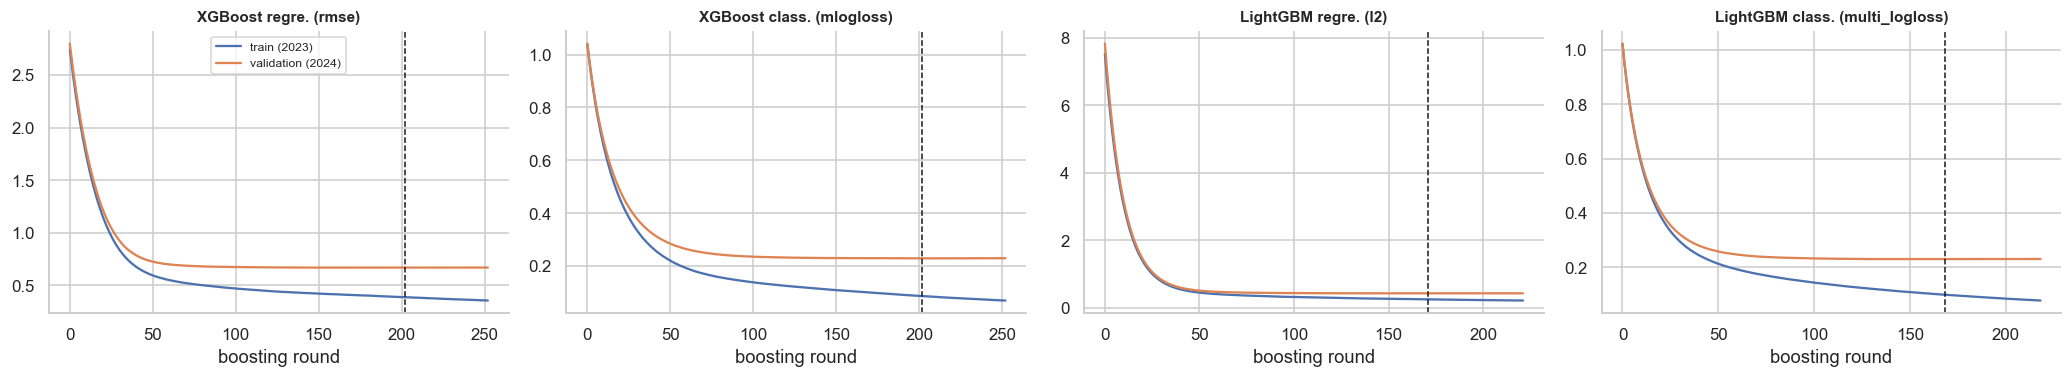

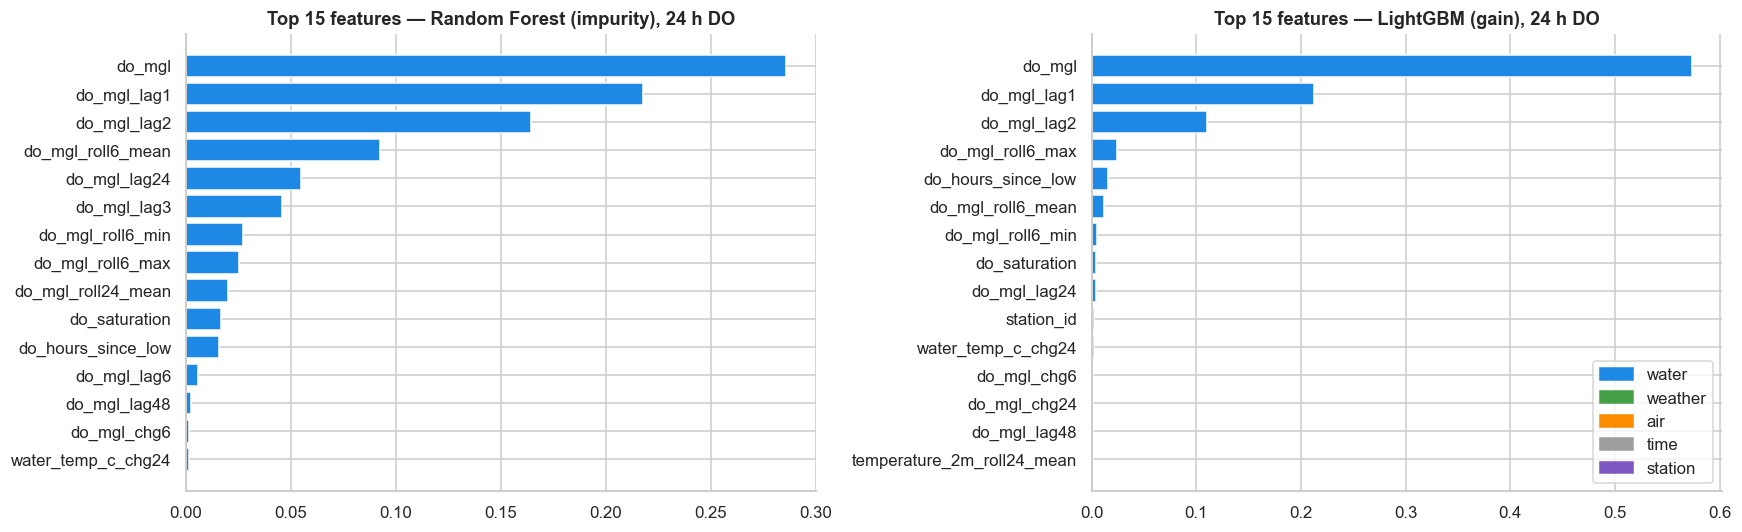

In [8]:
# @title 6.1 Boosting curves and feature importance
fig, axes = plt.subplots(1, 4, figsize=(19, 3.6))
for ax, (lib, task) in zip(axes, [("XGBoost", "regression"), ("XGBoost", "classification"), ("LightGBM", "regression"), ("LightGBM", "classification")]):
    ev = CURVES[(lib, task)]
    if lib == "XGBoost":
        m = list(ev["validation_0"])[0]; tr, va = ev["validation_0"][m], ev["validation_1"][m]
    else:
        m = list(ev["validation"])[0]; tr, va = ev["train"][m], ev["validation"][m]
    ax.plot(tr, label="train (2023)"); ax.plot(va, label="validation (2024)"); ax.axvline(int(np.argmin(va)), color="k", ls="--", lw=1)
    ax.set_title(f"{lib} {task[:5]}. ({m})", fontweight="bold", fontsize=10); ax.set_xlabel("boosting round")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

GROUP = {}
for f in FEATURES:
    GROUP[f] = ("station" if f.startswith("station") else "time" if f.startswith(("hour", "doy", "month", "dow")) else
                "air" if any(k in f for k in ["pm10", "pm2_5", "carbon", "nitrogen", "sulphur", "ozone", "aerosol", "dust"]) else
                "weather" if any(k in f for k in ["temperature_2m", "humidity", "precip", "pressure", "wind", "radiation", "soil", "et0", "rain"]) else "water")
COLS = {"water": "#1E88E5", "weather": "#43A047", "air": "#FB8C00", "time": "#9E9E9E", "station": "#7E57C2"}
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (imp, t) in zip(axes, [(RF_IMP, "Random Forest (impurity)"), (LGB_IMP, "LightGBM (gain)")]):
    top = (imp / imp.sum()).sort_values().tail(15)
    ax.barh(top.index, top.values, color=[COLS[GROUP[f]] for f in top.index]); ax.set_title(f"Top 15 features — {t}, 24 h DO", fontweight="bold")
axes[1].legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLS.values()], COLS.keys(), loc="lower right")
plt.tight_layout(); plt.show()

## 7. Models 4 and 5 of 5: BiLSTM and CNN-LSTM

Two multi-task sequence networks, trained on the GPU. **Input** for a forecast at time *t*: the last
**72 hours x 33 channels**, a learned **station embedding** of 8 numbers per river, and a hybrid branch
carrying the 211 engineered features at *t*. **Output**, in one forward pass: the DO change at all four
horizons and 4 x 3 class logits. The regression head predicts the *change*,
$\hat y = DO(t) + \text{out}\cdot\sigma_{DO}$, which removes the station's mean level from the problem.

**Loss** - masked MSE plus class-weighted cross-entropy, averaged over horizons so that missing targets
contribute nothing:
$$\mathcal{L} = \frac{1}{|\mathcal{H}|}\sum_{h}\frac{\sum_i m_{ih}(\hat\delta_{ih}-\delta_{ih})^2}{\sum_i m_{ih}} \;+\; \frac{1}{|\mathcal{H}|}\sum_h \Big(-\frac{\sum_i w_{y_{ih}} \log p_{ih}(y_{ih})}{\sum_i w_{y_{ih}}}\Big)$$

**Optimisation** - AdamW (lr 5e-4, weight decay 1e-4), dropout 0.3, ReduceLROnPlateau (x0.5, patience 2),
gradient clipping at 1.0, automatic mixed precision on the GPU, and early stopping on the 2024 validation
loss with patience 4.

### 7.1 Window construction

The deep models do not see the feature table directly; they see a 72-hour window of raw channels ending at the
forecast time. This cell builds those windows and fits both scalers on 2023 rows only.

In [9]:
# @title 7.1 Build 72-hour windows (scalers fitted on 2023 only)
from sklearn.preprocessing import StandardScaler
SEQ, NCH = 72, D["channels"].shape[1]
off, lens = D["offsets"], D["lengths"]
raw = D["channels"].astype("float32").copy()
start = pd.to_datetime(D["start"]); in2023 = np.zeros(len(raw), bool)
for i in range(len(STATIONS)):
    t = start[i] + pd.to_timedelta(np.arange(lens[i]), unit="h"); in2023[off[i]:off[i] + lens[i]] = (t.year == 2023)
med = np.nanmedian(raw[in2023], axis=0); raw = np.where(np.isnan(raw), med, raw)
ch_scaler = StandardScaler().fit(raw[in2023]); CH = ch_scaler.transform(raw).astype("float32")
do_scale = float(ch_scaler.scale_[list(D["channel_names"]).index("do_mgl")])

f_med = SPLITS["train"]["X"].median()
f_scaler = StandardScaler().fit(SPLITS["train"]["X"].fillna(f_med).fillna(0))
for s, d in SPLITS.items():
    d["F"] = np.nan_to_num(f_scaler.transform(d["X"].fillna(f_med).fillna(0))).astype("float32")
    yreg = np.stack([d["y"][:, col[f"y_reg_{h}"]] for h in H_ALL], 1)
    d["reg_t"] = ((yreg - d["do_now"][:, None]) / do_scale).astype("float32")          # scaled DO CHANGE, NaN if unknown
    yc = np.stack([d["y"][:, col[f"y_cls_{h}"]] for h in H_ALL], 1)
    d["cls_t"] = np.where(np.isnan(yc), -1, yc).astype("int64")                         # -1 = ignore
    d["start_idx"] = (off[d["station"]] + d["pos"] - SEQ + 1).astype("int64")

def batch(split, ids):
    d = SPLITS[split]; idx = d["start_idx"][ids][:, None] + np.arange(SEQ)[None, :]
    return (torch.from_numpy(CH[idx]), torch.from_numpy(d["station"][ids].astype("int64")), torch.from_numpy(d["F"][ids]),
            torch.from_numpy(d["reg_t"][ids]), torch.from_numpy(d["cls_t"][ids]))

x, st, f, r, c = batch("train", np.arange(4))
print(f"[OK] windows ready: one sample = {tuple(x.shape[1:])} hourly sequence + {f.shape[1]} features + station id")
print(f"     train {len(SPLITS['train']['X']):,} | val {len(SPLITS['val']['X']):,} | test {len(SPLITS['test']['X']):,} windows")

[OK] windows ready: one sample = (72, 33) hourly sequence + 211 features + station id
     train 63,818 | val 63,408 | test 63,497 windows


### 7.2 Architectures and the multi-task loss

In [10]:
# @title 7.2 Network architectures and the multi-task loss
N_ST, N_H, N_CLS = len(STATIONS), len(H_ALL), 3

class Heads(nn.Module):
    def __init__(self, width, dense=64, p=0.3):
        super().__init__(); self.body = nn.Sequential(nn.Linear(width, dense), nn.ReLU(), nn.Dropout(p))
        self.reg, self.cls = nn.Linear(dense, N_H), nn.Linear(dense, N_H * N_CLS)
    def forward(self, z):
        z = self.body(z); return self.reg(z), self.cls(z).view(-1, N_H, N_CLS)

class BiLSTM(nn.Module):
    def __init__(self, hidden=32, p=0.3):
        super().__init__(); self.emb = nn.Embedding(N_ST, 8)
        self.lstm = nn.LSTM(NCH, hidden, num_layers=2, bidirectional=True, dropout=p, batch_first=True)
        self.feat = nn.Sequential(nn.Linear(len(FEATURES), 64), nn.ReLU(), nn.Dropout(p)); self.heads = Heads(2 * hidden + 8 + 64, p=p)
    def forward(self, x, s, f):
        _, (h, _) = self.lstm(x); return self.heads(torch.cat([h[-2], h[-1], self.emb(s), self.feat(f)], 1))

class CNNLSTM(nn.Module):
    def __init__(self, hidden=32, p=0.3):
        super().__init__(); self.emb = nn.Embedding(N_ST, 8)
        self.conv = nn.Sequential(nn.Conv1d(NCH, 32, 3, padding=1), nn.ReLU(), nn.Conv1d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool1d(2))
        self.lstm = nn.LSTM(64, hidden, batch_first=True)
        self.feat = nn.Sequential(nn.Linear(len(FEATURES), 64), nn.ReLU(), nn.Dropout(p)); self.heads = Heads(hidden + 8 + 64, p=p)
    def forward(self, x, s, f):
        z = self.conv(x.transpose(1, 2)); _, (h, _) = self.lstm(z.transpose(1, 2))
        return self.heads(torch.cat([h[-1], self.emb(s), self.feat(f)], 1))

cls_tr = SPLITS["train"]["cls_t"]
CW = torch.tensor([[len(c[c >= 0]) / (3 * max((c == k).sum(), 1)) for k in range(3)] for c in cls_tr.T], dtype=torch.float32, device=device)

def multitask_loss(reg_out, cls_out, reg_t, cls_t):
    m = ~torch.isnan(reg_t)
    per_h = (((reg_out - torch.nan_to_num(reg_t)) ** 2) * m).sum(0) / m.sum(0).clamp(min=1)
    reg_loss = per_h[m.any(0)].mean()
    ce = [nn.functional.cross_entropy(cls_out[cls_t[:, j] >= 0, j], cls_t[cls_t[:, j] >= 0, j], weight=CW[j])
          for j in range(N_H) if (cls_t[:, j] >= 0).any()]
    return reg_loss + torch.stack(ce).mean()

for k in [BiLSTM, CNNLSTM]:
    print(f"{k.__name__:<8}: {sum(p.numel() for p in k().parameters()):,} trainable parameters")
print(BiLSTM())

BiLSTM  : 65,856 trainable parameters
CNNLSTM : 43,520 trainable parameters
BiLSTM(
  (emb): Embedding(30, 8)
  (lstm): LSTM(33, 32, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (feat): Sequential(
    (0): Linear(in_features=211, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
  )
  (heads): Heads(
    (body): Sequential(
      (0): Linear(in_features=136, out_features=64, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.3, inplace=False)
    )
    (reg): Linear(in_features=64, out_features=4, bias=True)
    (cls): Linear(in_features=64, out_features=12, bias=True)
  )
)


### 7.3 Training both networks

[transformers] Disabling PyTorch because PyTorch >= 2.4 is required but found 2.2.2+cu121


[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.



=== BILSTM (65,856 params) on cuda ===


  epoch  1 | train loss 0.8732 | val loss 0.4866 | val RMSE 24 h 0.7192 |  6.6s


  epoch  2 | train loss 0.5103 | val loss 0.4127 | val RMSE 24 h 0.7140 |  6.0s


...

  epoch  7 | train loss 0.3894 | val loss 0.3517 | val RMSE 24 h 0.6894 |  4.1s


  epoch  8 | train loss 0.3802 | val loss 0.3452 | val RMSE 24 h 0.6866 |  4.1s


  epoch  9 | train loss 0.3733 | val loss 0.3471 | val RMSE 24 h 0.6849 |  4.5s


  epoch 10 | train loss 0.3679 | val loss 0.3438 | val RMSE 24 h 0.6816 |  4.2s
  kept epoch 10 (lowest validation loss 0.3438)


------------------------------------------------------------------------------
7.  CNN-LSTM  |  val split (2024), 24 h ahead  |  trained in 48.2 s
  regression     R2 0.9460  RMSE 0.6816  MAE 0.4219  NSE 0.9460  Skill vs persistence 0.0721
  classification Accuracy 0.8906  Precision (macro) 0.8684  Recall (macro) 0.8873  F1 (macro) 0.8761  ROC-AUC (macro OvR) 0.9762
------------------------------------------------------------------------------


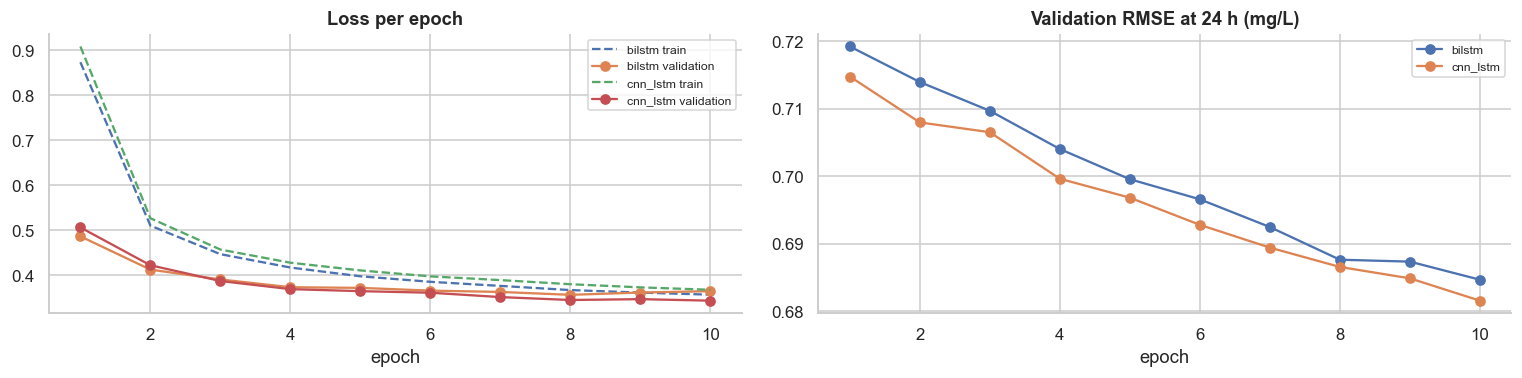

In [11]:
# @title 7.3 Train both networks (GPU, mixed precision, early stopping on 2024)
MAX_EPOCHS, PATIENCE, BS = (10 if FAST_DEMO else 15), 4, 512
use_amp = device.type == "cuda"

def run(model, split, train=False, opt=None, scaler=None):
    n = len(SPLITS[split]["X"]); order = np.random.permutation(n) if train else np.arange(n)
    model.train(train); tot, nb = 0.0, 0
    reg_p = np.empty((n, N_H), "float32"); cls_p = np.empty((n, N_H, N_CLS), "float32")
    for b in range(0, n, BS):
        ids = order[b:b + BS]; x, s, f, r, c = [t.to(device, non_blocking=True) for t in batch(split, ids)]
        with torch.set_grad_enabled(train), torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
            ro, co = model(x, s, f); loss = multitask_loss(ro.float(), co.float(), r, c)
        if train:
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update()
        else:
            reg_p[ids] = ro.float().detach().cpu().numpy(); cls_p[ids] = torch.softmax(co.float(), 2).detach().cpu().numpy()
        tot += loss.item(); nb += 1
    return tot / nb, reg_p, cls_p

HIST = {}
for name, Net in [("bilstm", BiLSTM), ("cnn_lstm", CNNLSTM)]:
    torch.manual_seed(SEED); np.random.seed(SEED)
    model = Net().to(device); opt = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    best, bad, hist, t0 = (np.inf, None, 0), 0, [], time.perf_counter()
    print(f"\n=== {name.upper()} ({sum(p.numel() for p in model.parameters()):,} params) on {device} ===")
    for ep in range(1, MAX_EPOCHS + 1):
        te = time.perf_counter(); tl, _, _ = run(model, "train", True, opt, scaler); vl, rp, cp = run(model, "val")
        sched.step(vl)
        j = H_ALL.index(H); pred_do = SPLITS["val"]["do_now"] + rp[:, j] * do_scale
        yv = SPLITS["val"]["y"][:, col[f"y_reg_{H}"]]; ok = ~np.isnan(yv); rmse = np.sqrt(np.mean((pred_do[ok] - yv[ok]) ** 2))
        hist.append({"epoch": ep, "train_loss": tl, "val_loss": vl, "val_rmse_24": rmse})
        print(f"  epoch {ep:>2} | train loss {tl:.4f} | val loss {vl:.4f} | val RMSE 24 h {rmse:.4f} | {time.perf_counter() - te:4.1f}s")
        if vl < best[0] - 1e-6:
            best, bad = (vl, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, ep), 0
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"  early stopping - no improvement for {PATIENCE} epochs"); break
    model.load_state_dict(best[1]); print(f"  kept epoch {best[2]} (lowest validation loss {best[0]:.4f})")
    out = {}; j = H_ALL.index(H)
    for s in ["val", "test"]:
        _, rp, cp = run(model, s); out[f"{s}_reg"] = SPLITS[s]["do_now"] + rp[:, j] * do_scale; out[f"{s}_proba"] = cp[:, j, :]
    PRED[name] = out; HIST[name] = pd.DataFrame(hist); TIMES[{"bilstm": "BiLSTM", "cnn_lstm": "CNN-LSTM"}[name]] = time.perf_counter() - t0
    globals()[f"MODEL_{name.upper()}"] = model
    VAL_SUMMARY[name] = summarise(f"7.  {'BiLSTM' if name == 'bilstm' else 'CNN-LSTM'}", "val",
                                  out["val_reg"], out["val_proba"], seconds=TIMES[{"bilstm": "BiLSTM",
                                  "cnn_lstm": "CNN-LSTM"}[name]])

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for name, h in HIST.items():
    axes[0].plot(h.epoch, h.train_loss, "--", label=f"{name} train"); axes[0].plot(h.epoch, h.val_loss, "-o", label=f"{name} validation")
    axes[1].plot(h.epoch, h.val_rmse_24, "-o", label=name)
axes[0].set_title("Loss per epoch", fontweight="bold"); axes[1].set_title("Validation RMSE at 24 h (mg/L)", fontweight="bold")
for a in axes: a.set_xlabel("epoch"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Ensemble Learning

The five models are now fixed. This section learns how to combine them, and it is where the project's two
final systems are built. Both are fitted on **2024 only** - a year none of the base models was trained on, so
the combiner sees honest out-of-sample behaviour - and 2025 is not read until Section 9.

The two tasks get different combiners, because what works for a continuous target and for a probability
simplex is not the same thing:

- **8.1 Regression** - a **Ridge stacking meta-learner** on the five DO forecasts. A linear meta-model is the
  right amount of capacity when the inputs are already five strong forecasts of the same quantity.
- **8.2 Classification** - **Caruana greedy ensemble selection with replacement** on the five probability
  vectors. This is the algorithm behind the project's `ensemble_v21`, and it is implemented inline below so
  this notebook is self-contained.

### 8.1 Regression ensemble: Ridge stacking

The meta-learner fits one coefficient per member plus an intercept on the 2024 forecasts,

$$\hat y_{\text{DO}} = \beta_0 + \sum_{k=1}^{5}\beta_k\,\hat y_k$$

with a small L2 penalty so that correlated members cannot produce wild offsetting weights. A negative
coefficient is not a bug: it means the meta-learner uses that member to correct the others rather than to vote.

This cell also fits the **warning threshold** `tau` used by the deployed early-warning service: the value of
`P(Low) >= tau` that catches the most onsets on 2024 inside a 1.8 % false-alarm budget. It is reported here for
completeness and is used only by the single-hour demo in Section 12; none of the metric tables below use it.

In [12]:
# @title 8.1 Regression ensemble - Ridge stacking on the 2024 forecasts
from sklearn.linear_model import Ridge, LogisticRegression

MEMBERS = ["random_forest", "xgboost", "lightgbm", "bilstm", "cnn_lstm"]
NICE = {"random_forest": "Random Forest", "xgboost": "XGBoost", "lightgbm": "LightGBM", "bilstm": "BiLSTM",
        "cnn_lstm": "CNN-LSTM", "simple_average": "Simple average", "stacking": "Stacking ensemble",
        "ensemble_v21": "Greedy ensemble (ensemble_v21)", "persistence": "Persistence (no change)"}

Rm = {s: np.column_stack([PRED[m][f"{s}_reg"] for m in MEMBERS]) for s in ["val", "test"]}
Pm = {s: np.stack([PRED[m][f"{s}_proba"] for m in MEMBERS], 1) for s in ["val", "test"]}   # (n, 5, 3)
Pflat = {s: Pm[s].reshape(len(Pm[s]), -1) for s in ["val", "test"]}
yv_r = SPLITS["val"]["y"][:, col[f"y_reg_{H}"]]
yv_c = SPLITS["val"]["y"][:, col[f"y_cls_{H}"]]

ok = ~np.isnan(yv_r) & ~np.isnan(Rm["val"]).any(1)
ridge = Ridge(alpha=1.0).fit(Rm["val"][ok], yv_r[ok])
ok_c = ~np.isnan(yv_c) & ~np.isnan(Pflat["val"]).any(1)
logit = LogisticRegression(max_iter=1000, class_weight="balanced",
                           random_state=SEED).fit(Pflat["val"][ok_c], yv_c[ok_c].astype(int))


def safe(f, X, width=None):
    out = np.full(len(X) if width is None else (len(X), width), np.nan)
    g = ~np.isnan(X).any(1); out[g] = f(X[g]); return out


for s in ["val", "test"]:
    PRED.setdefault("stacking", {})[f"{s}_reg"] = safe(ridge.predict, Rm[s])
    PRED["stacking"][f"{s}_proba"] = safe(logit.predict_proba, Pflat[s], 3)
    PRED.setdefault("simple_average", {})[f"{s}_reg"] = Rm[s].mean(1)
    PRED["simple_average"][f"{s}_proba"] = Pm[s].mean(1)

print("Ridge coefficients on the five members' 24 h DO forecasts, fitted on 2024:")
for m, w in zip(MEMBERS, ridge.coef_):
    print(f"  {NICE[m]:<16} {w:+.4f}")
print(f"  {'intercept':<16} {ridge.intercept_:+.4f}")


def apply_rule(p, tau):
    """The warning rule: predict Low when P(Low) >= tau, otherwise the argmax of the other two."""
    pred = 1 + np.nan_to_num(p[:, 1:], nan=-1).argmax(1)
    pred[p[:, 0] >= tau] = 0
    return pred


best = None
for tau in np.arange(0.05, 0.951, 0.01):
    e = early_warning(SPLITS["val"]["class_now"], yv_c, apply_rule(PRED["stacking"]["val_proba"], tau))
    if e["false_alarm"] <= 0.018 and (best is None or (e["onset_recall"], -e["false_alarm"]) > (best[1], -best[2])):
        best = (round(float(tau), 2), e["onset_recall"], e["false_alarm"])
TAU = best[0]
print(f"\nWarning threshold fitted on 2024: tau = {TAU:.2f} "
      f"(2024 onset recall {best[1]:.3f}, false alarms {best[2] * 100:.2f} %). "
      f"Used only by the Section 12 demo.")

VAL_SUMMARY["stacking"] = summarise(
    "8.1  Ridge stacking ensemble", "val", PRED["stacking"]["val_reg"], PRED["stacking"]["val_proba"],
    note="the regression row is the final regression system; the classification row is the logistic "
         "stacking meta-model, shown for reference only - the final classifier is Section 8.2")

Ridge coefficients on the five members' 24 h DO forecasts, fitted on 2024:
  Random Forest    -0.0934
  XGBoost          +0.2477
  LightGBM         +0.5631
  BiLSTM           -0.0536
  CNN-LSTM         +0.3452
  intercept        -0.0442



Warning threshold fitted on 2024: tau = 0.23 (2024 onset recall 0.520, false alarms 1.72 %). Used only by the Section 12 demo.
------------------------------------------------------------------------------
8.1  Ridge stacking ensemble  |  val split (2024), 24 h ahead
  note: the regression row is the final regression system; the classification row is the logistic stacking meta-model, shown for reference only - the final classifier is Section 8.2
  regression     R2 0.9510  RMSE 0.6495  MAE 0.4010  NSE 0.9510  Skill vs persistence 0.1158
  classification Accuracy 0.9071  Precision (macro) 0.8868  Recall (macro) 0.8989  F1 (macro) 0.8923  ROC-AUC (macro OvR) 0.9812
------------------------------------------------------------------------------


### 8.2 Classification ensemble: Caruana greedy ensemble selection

Stacking a logistic meta-model on fifteen probability inputs has enough freedom to overfit a single tuning
year. The classification ensemble therefore uses **greedy ensemble selection with replacement**
(Caruana et al., 2004), which searches a far smaller space: the only ensembles it can reach are uniform
averages over a multiset of members, so the weights are always non-negative, sum to one, and come in units of
`1 / n_selections`.

The algorithm, implemented inline below and identical in behaviour to `greedy_select` in
`src/models/ensemble_v21.py`:

1. **Start** from the single member with the best 2024 macro F1.
2. **Repeat** up to 30 times: try adding each member to the current bag, *repeats allowed* - that is what
   "with replacement" means, and it is how a fixed-step greedy search reaches non-uniform weights - and keep
   the addition that improves 2024 macro F1 the most.
3. **Stop** the moment no addition strictly improves the score. Because step 1 starts from the best single
   member and an addition is only ever accepted on a strict improvement, the search can never end up worse
   than the best individual model.
4. **The weights** are the selection counts divided by their total.

Only 2024 decides the weights. The score is macro F1 under the plain `argmax` rule, matching the metric tables
in Section 9 and in the evaluation notebook. (The official run in `src/models/ensemble_v21.py` scores the
candidate under the operational warning rule instead, re-tuning `tau` inside the loop; the search itself is
the same and it selects the same kind of blend.)

In [13]:
# @title 8.2 Classification ensemble - Caruana greedy selection with replacement (inline)
MAX_ITERS = 30


def macro_f1_2024(proba):
    """The 2024 macro F1 of a candidate ensemble under the argmax rule."""
    ok = ~np.isnan(yv_c) & ~np.isnan(proba).any(1)
    return float(f1_score(yv_c[ok].astype(int), proba[ok].argmax(1), average="macro"))


def greedy_select(P_val, member_names, max_iters=MAX_ITERS):
    """
    Caruana greedy ensemble selection with replacement.

    P_val is (n_rows, n_members, n_classes) of 2024 probabilities. Returns the selection counts, the
    normalised weights and the full trace of the search.
    """
    n_members = P_val.shape[1]

    # step 1: the best single member on 2024
    singles = [macro_f1_2024(P_val[:, j, :]) for j in range(n_members)]
    first = int(np.argmax(singles))
    counts = np.zeros(n_members, dtype="int64"); counts[first] = 1
    acc = P_val[:, first, :].astype("float64").copy()
    total, best = 1, singles[first]
    trace = [{"iteration": 0, "added": member_names[first], "macro_F1_2024": best}]

    print("  single-member macro F1 on 2024:")
    for j, s in enumerate(singles):
        print(f"    {NICE[member_names[j]]:<16} {s:.6f}{'   <- best single, bag starts here' if j == first else ''}")
    print(f"\n  iteration  0  start  {member_names[first]:<14}  macro F1 {best:.6f}")

    # step 2: add the most helpful member, repeats allowed, while it strictly improves
    for it in range(1, max_iters + 1):
        cand = [macro_f1_2024((acc + P_val[:, j, :]) / (total + 1)) for j in range(n_members)]
        j = int(np.argmax(cand))
        if not cand[j] > best:
            print(f"  iteration {it:>2}  stop   no addition improves ({cand[j]:.6f} <= {best:.6f})")
            break
        acc = acc + P_val[:, j, :]; total += 1; counts[j] += 1; best = cand[j]
        trace.append({"iteration": it, "added": member_names[j], "macro_F1_2024": best})
        print(f"  iteration {it:>2}  add    {member_names[j]:<14}  macro F1 {best:.6f}  "
              f"(+{best - trace[-2]['macro_F1_2024']:.6f})")
    else:
        print(f"  reached the {max_iters}-iteration limit")

    return counts, counts / total, best, pd.DataFrame(trace)


print("Caruana greedy ensemble selection with replacement - weights chosen on 2024 only")
print("=" * 78)
GREEDY_COUNTS, GREEDY_W, GREEDY_VAL_F1, GREEDY_TRACE = greedy_select(Pm["val"], MEMBERS)
print("=" * 78)

weights = pd.DataFrame({"selections": GREEDY_COUNTS, "weight": GREEDY_W},
                       index=[NICE[m] for m in MEMBERS])
display(Markdown(f"**Final weights of the classification ensemble** "
                 f"({GREEDY_COUNTS.sum()} selections, 2024 macro F1 {GREEDY_VAL_F1:.6f}):"))
display(weights.style.format({"selections": "{:.0f}", "weight": "{:.4f}"})
        .apply(lambda s: ["font-weight:bold;background-color:#E8F5E9;" if GREEDY_W[i] > 0 else ""
                          for i in range(len(MEMBERS))], axis=0))

for s in ["val", "test"]:
    PRED.setdefault("ensemble_v21", {})[f"{s}_proba"] = (Pm[s] * GREEDY_W[None, :, None]).sum(1)
    PRED["ensemble_v21"][f"{s}_reg"] = (Rm[s] * GREEDY_W[None, :]).sum(1)

assert abs(macro_f1_2024(PRED["ensemble_v21"]["val_proba"]) - GREEDY_VAL_F1) < 1e-9, \
    "the final weights do not reproduce the score the search reached"
best_single_f1 = max(macro_f1_2024(Pm["val"][:, j, :]) for j in range(len(MEMBERS)))
assert GREEDY_VAL_F1 >= best_single_f1 - 1e-12, "the greedy ensemble is worse than the best single member"
print(f"[PASS] the weights reproduce the search score, and the ensemble is at least as good as the best "
      f"single member on 2024 ({GREEDY_VAL_F1:.6f} >= {best_single_f1:.6f})")

VAL_SUMMARY["ensemble_v21"] = summarise(
    "8.2  Greedy ensemble (ensemble_v21)", "val", PRED["ensemble_v21"]["val_reg"],
    PRED["ensemble_v21"]["val_proba"],
    note="the classification row is the final classification system; the regression row applies the same "
         "weights to the DO forecasts, shown for reference only - the final regressor is Section 8.1")

Caruana greedy ensemble selection with replacement - weights chosen on 2024 only


  single-member macro F1 on 2024:
    Random Forest    0.890571
    XGBoost          0.892719   <- best single, bag starts here
    LightGBM         0.891762
    BiLSTM           0.874581
    CNN-LSTM         0.876114

  iteration  0  start  xgboost         macro F1 0.892719


  iteration  1  add    random_forest   macro F1 0.893794  (+0.001075)


  iteration  2  add    lightgbm        macro F1 0.894337  (+0.000542)


  iteration  3  add    xgboost         macro F1 0.894558  (+0.000222)


  iteration  4  stop   no addition improves (0.894304 <= 0.894558)


**Final weights of the classification ensemble** (4 selections, 2024 macro F1 0.894558):

,selections,weight
Random Forest,1,0.2500
XGBoost,2,0.5000
LightGBM,1,0.2500
BiLSTM,0,0.0000
CNN-LSTM,0,0.0000


[PASS] the weights reproduce the search score, and the ensemble is at least as good as the best single member on 2024 (0.894558 >= 0.892719)


------------------------------------------------------------------------------
8.2  Greedy ensemble (ensemble_v21)  |  val split (2024), 24 h ahead
  note: the classification row is the final classification system; the regression row applies the same weights to the DO forecasts, shown for reference only - the final regressor is Section 8.1
  regression     R2 0.9501  RMSE 0.6556  MAE 0.4062  NSE 0.9501  Skill vs persistence 0.1076
  classification Accuracy 0.9100  Precision (macro) 0.8903  Recall (macro) 0.8995  F1 (macro) 0.8946  ROC-AUC (macro OvR) 0.9819
------------------------------------------------------------------------------


## 9. Evaluation on the Unseen 2025 Test Year

Nothing below was fitted, tuned or inspected on 2025. The base models were fitted on 2023, their stopping
rounds and epochs chosen on 2024, and both ensembles weighted on 2024. This is the first and only time the
test year is read.

The two tasks are reported in separate tables, each with its own five metrics, because they answer different
questions and share no units. Classification uses the plain `argmax` rule throughout.

### 9.1 Regression on 2025

Every model, plus the simple average and both ensembles, on the same scored hours. The bold row is the final
regression system. `ensemble_v21` appears here only because its weights can also be applied to the DO
forecasts; it is not the regression system.

In [14]:
# @title 9.1 Regression results on the unseen 2025 test year
d = SPLITS["test"]
yt_r = d["y"][:, col[f"y_reg_{H}"]]
yt_c = d["y"][:, col[f"y_cls_{H}"]]
ok_r = ~np.isnan(yt_r)

# persistence: the no-change forecast, and its class read straight off the current band
pers_proba = np.full((len(d["X"]), 3), np.nan)
known = ~np.isnan(d["class_now"])
pers_proba[known] = np.eye(3)[d["class_now"][known].astype(int)]
PRED["persistence"] = {"test_reg": d["do_now"].astype("float64"), "test_proba": pers_proba}

ORDER = ["persistence"] + MEMBERS + ["simple_average", "stacking", "ensemble_v21"]
TEST = {m: evaluate("test", PRED[m].get("test_reg"), PRED[m].get("test_proba")) for m in ORDER}

reg_table = pd.DataFrame({NICE[m]: {k: TEST[m][k] for k in REG_KEYS} for m in ORDER}).T
print("=" * 86)
print(f"REGRESSION - blind 2025 test year - {H} h ahead - {ok_r.sum():,} scored hours "
      f"(demo pack: every 4th hour, 30 stations)")
print("=" * 86)
display(reg_table.style.format("{:.4f}")
        .highlight_min(subset=["RMSE", "MAE"], color="#C8E6C9")
        .highlight_max(subset=["R2", "NSE", "Skill vs persistence"], color="#C8E6C9")
        .apply(lambda s: ["font-weight:bold;" if i == NICE["stacking"] else "" for i in s.index], axis=0))
print(f"Final regression system: {NICE['stacking']} - "
      + ", ".join(f"{k} {reg_table.loc[NICE['stacking'], k]:.4f}" for k in REG_KEYS))

REGRESSION - blind 2025 test year - 24 h ahead - 62,924 scored hours (demo pack: every 4th hour, 30 stations)


,R2,RMSE,MAE,NSE,Skill vs persistence
Persistence (no change),0.9380,0.7522,0.4559,0.9380,0.0000
Random Forest,0.9448,0.7102,0.4309,0.9448,0.0559
XGBoost,0.9418,0.7288,0.4413,0.9418,0.0311
LightGBM,0.9470,0.6957,0.4268,0.9470,0.0752
BiLSTM,0.9453,0.7067,0.4335,0.9453,0.0605
CNN-LSTM,0.9464,0.6998,0.4272,0.9464,0.0697
Simple average,0.9485,0.6859,0.4180,0.9485,0.0882
Stacking ensemble,0.9490,0.6823,0.4165,0.9490,0.0929
Greedy ensemble (ensemble_v21),0.9457,0.7043,0.4276,0.9457,0.0637


Final regression system: Stacking ensemble - R2 0.9490, RMSE 0.6823, MAE 0.4165, NSE 0.9490, Skill vs persistence 0.0929


### 9.2 Classification on 2025 (argmax rule)

The same models on the 3-class task. The bold row is the final classification system. Persistence here means
"the band it is in now is the band it will be in", which is a strong baseline at 24 h because of the daily
cycle, and a weak one at the horizons where the river is actually changing.

In [15]:
# @title 9.2 Classification results on the unseen 2025 test year
cls_table = pd.DataFrame({NICE[m]: {k: TEST[m][k] for k in CLS_KEYS} for m in ORDER}).T
print("=" * 86)
print(f"CLASSIFICATION - blind 2025 test year - {H} h ahead - argmax rule "
      f"({(~np.isnan(yt_c)).sum():,} scored hours)")
print("=" * 86)
display(cls_table.style.format("{:.4f}", na_rep="n/a")
        .highlight_max(subset=CLS_KEYS, color="#C8E6C9")
        .apply(lambda s: ["font-weight:bold;" if i == NICE["ensemble_v21"] else "" for i in s.index], axis=0))
print("Persistence has no probability output, so its ROC-AUC is undefined and shown as n/a.")
print(f"Final classification system: {NICE['ensemble_v21']} - "
      + ", ".join(f"{k} {cls_table.loc[NICE['ensemble_v21'], k]:.4f}" for k in CLS_KEYS))

CLASSIFICATION - blind 2025 test year - 24 h ahead - argmax rule (62,924 scored hours)


,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (macro OvR)
Persistence (no change),0.9004,0.8802,0.8803,0.8802,n/a
Random Forest,0.9055,0.8844,0.8940,0.8889,0.9803
XGBoost,0.9080,0.8882,0.8955,0.8916,0.9812
LightGBM,0.9066,0.8869,0.8940,0.8901,0.9814
BiLSTM,0.8859,0.8621,0.8716,0.8663,0.9721
CNN-LSTM,0.8792,0.8553,0.8764,0.8637,0.9729
Simple average,0.9045,0.8838,0.8950,0.8889,0.9805
Stacking ensemble,0.9049,0.8839,0.8959,0.8893,0.9803
Greedy ensemble (ensemble_v21),0.9083,0.8883,0.8959,0.8918,0.9816


Persistence has no probability output, so its ROC-AUC is undefined and shown as n/a.
Final classification system: Greedy ensemble (ensemble_v21) - Accuracy 0.9083, Precision (macro) 0.8883, Recall (macro) 0.8959, F1 (macro) 0.8918, ROC-AUC (macro OvR) 0.9816


### 9.3 Final system summary

The deployed system is not one model: regression is served by the Ridge stacking ensemble and classification by
the greedy ensemble. The table below is the demo-pack counterpart of Section 4.2 of the evaluation notebook.

**Final system on the blind 2025 test year of the demo pack.** The regression column is `stacking`; the classification column is `ensemble_v21` under `argmax`.

,Regression - stacking ensemble,Classification - ensemble_v21 (argmax)
R2,0.9490,
RMSE,0.6823,
MAE,0.4165,
NSE,0.9490,
Skill vs persistence,0.0929,
Accuracy,,0.9083
Precision (macro),,0.8883
Recall (macro),,0.8959
F1 (macro),,0.8918
ROC-AUC (macro OvR),,0.9816


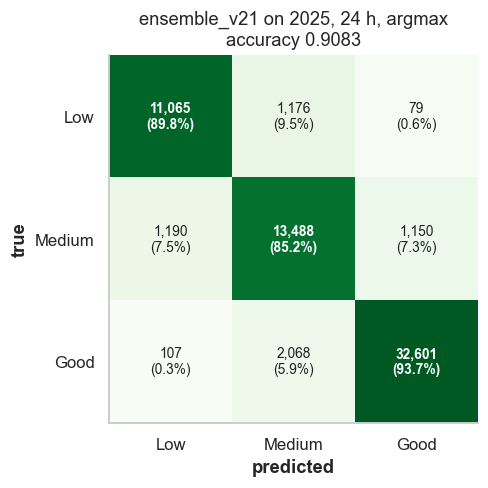

In [16]:
# @title 9.3 Final system - the ten reported metrics on 2025
final = pd.DataFrame({
    "Regression - stacking ensemble": {**{k: TEST["stacking"][k] for k in REG_KEYS},
                                       **{k: np.nan for k in CLS_KEYS}},
    "Classification - ensemble_v21 (argmax)": {**{k: np.nan for k in REG_KEYS},
                                               **{k: TEST["ensemble_v21"][k] for k in CLS_KEYS}},
})
display(Markdown("**Final system on the blind 2025 test year of the demo pack.** The regression column is "
                 "`stacking`; the classification column is `ensemble_v21` under `argmax`."))
display(final.style.format("{:.4f}", na_rep=""))

cm = confusion_matrix(yt_c[~np.isnan(yt_c)].astype(int),
                      PRED["ensemble_v21"]["test_proba"][~np.isnan(yt_c)].argmax(1), labels=[0, 1, 2])
pct = cm / cm.sum(1, keepdims=True) * 100
fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.imshow(pct, cmap="Greens", vmin=0, vmax=100)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]:,}\n({pct[i, j]:.1f}%)", ha="center", va="center", fontsize=9,
                fontweight="bold" if i == j else "normal", color="white" if pct[i, j] > 55 else "#212121")
ax.set_xticks(range(3), CLASSES); ax.set_yticks(range(3), CLASSES); ax.grid(False)
ax.set_xlabel("predicted", fontweight="bold"); ax.set_ylabel("true", fontweight="bold")
ax.set_title(f"ensemble_v21 on 2025, {H} h, argmax\naccuracy {TEST['ensemble_v21']['Accuracy']:.4f}")
plt.tight_layout(); plt.show()

## 10. Demo Run vs Official Full Run

The demo pack keeps one hour in four, so this notebook trains on roughly a quarter of the rows the official run
used, with 100 trees instead of 300 and at most 10 epochs instead of 15. The official numbers below are the
24-hour values from `results/test_v21/metrics_regression_stage2.csv` and
`results/test_v21/metrics_classification_stage2.csv`, hard-coded here so the comparison works offline.

**The demo pack is a subset of the data, so small differences from the official numbers are expected**; what
should carry over is the ordering of the models and the fact that each ensemble lands at or above its best
member.

**Demo pack (every 4th hour, reduced capacity) against the official full run.** Source of the official column: `results/test_v21/`, 24 h, `argmax`.

,RMSE demo,RMSE official,R2 demo,R2 official,macro F1 demo,macro F1 official,accuracy demo,accuracy official
model,,,,,,,,
Random Forest,0.7102,0.6924,0.9448,0.9475,0.8889,0.8928,0.9055,0.9088
XGBoost,0.7288,0.6951,0.9418,0.9471,0.8916,0.8934,0.9080,0.9088
LightGBM,0.6957,0.6822,0.9470,0.9490,0.8901,0.8936,0.9066,0.9088
BiLSTM,0.7067,0.6887,0.9453,0.9480,0.8663,0.8810,0.8859,0.8971
CNN-LSTM,0.6998,0.6860,0.9464,0.9484,0.8637,0.8804,0.8792,0.8967
Simple average,0.6859,0.6737,0.9485,0.9503,0.8889,0.8928,0.9045,0.9078
Stacking ensemble,0.6823,0.6718,0.9490,0.9505,0.8893,0.8930,0.9049,0.9081
Greedy ensemble (ensemble_v21),0.7043,0.6730,0.9457,0.9504,0.8918,0.8941,0.9083,0.9093


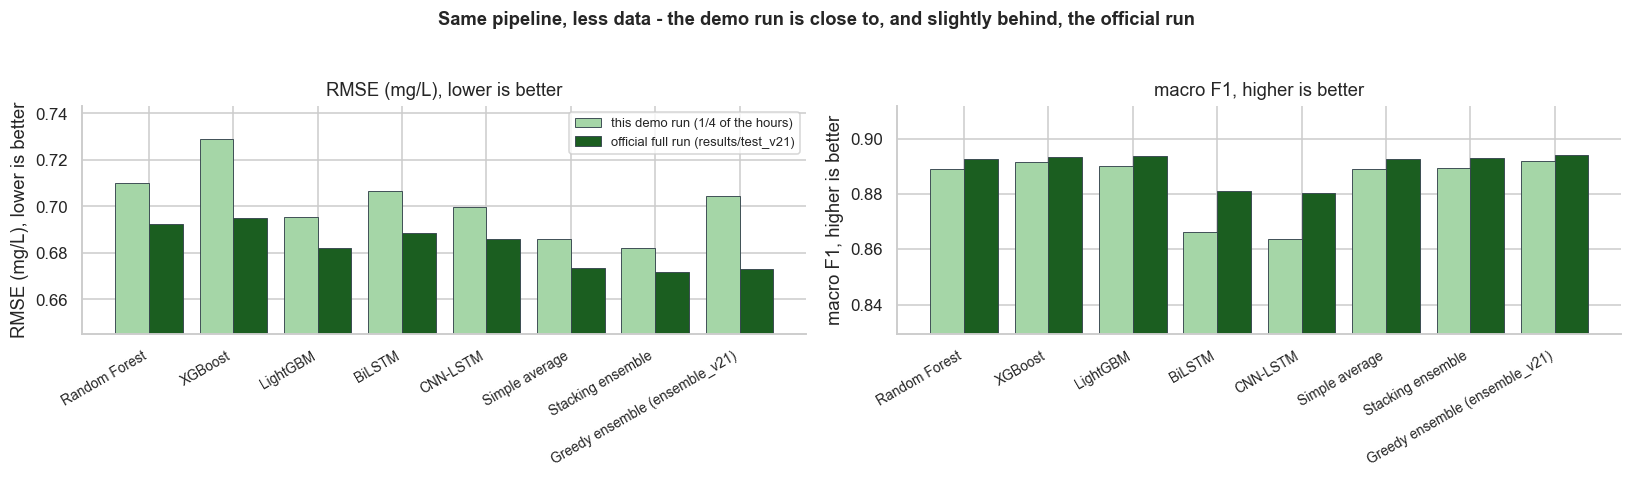

The demo pack is a subset of the full dataset (one hour in four, 100 RF trees, at most 10 epochs), so small differences from the official numbers are expected.


In [17]:
# @title 10. This run vs the official full-dataset results (2025, 24 h)
# Official 24 h values, copied at build time from results/test_v21/metrics_regression_stage2.csv
# and results/test_v21/metrics_classification_stage2.csv (rule == "argmax").
OFFICIAL = json.loads('{"random_forest": {"rmse": 0.6924, "r2": 0.9475, "mae": 0.4189, "accuracy": 0.9088, "f1_macro": 0.8928, "roc_auc_ovr_macro": 0.9815}, "xgboost": {"rmse": 0.6951, "r2": 0.9471, "mae": 0.4207, "accuracy": 0.9088, "f1_macro": 0.8934, "roc_auc_ovr_macro": 0.9821}, "lightgbm": {"rmse": 0.6822, "r2": 0.949, "mae": 0.4158, "accuracy": 0.9088, "f1_macro": 0.8936, "roc_auc_ovr_macro": 0.9823}, "bilstm": {"rmse": 0.6887, "r2": 0.948, "mae": 0.4197, "accuracy": 0.8971, "f1_macro": 0.881, "roc_auc_ovr_macro": 0.9783}, "cnn_lstm": {"rmse": 0.686, "r2": 0.9484, "mae": 0.4159, "accuracy": 0.8967, "f1_macro": 0.8804, "roc_auc_ovr_macro": 0.9791}, "simple_average": {"rmse": 0.6737, "r2": 0.9503, "mae": 0.4086, "accuracy": 0.9078, "f1_macro": 0.8928, "roc_auc_ovr_macro": 0.9822}, "stacking": {"rmse": 0.6718, "r2": 0.9505, "mae": 0.4074, "accuracy": 0.9081, "f1_macro": 0.893, "roc_auc_ovr_macro": 0.9815}, "ensemble_v21": {"rmse": 0.673, "r2": 0.9504, "mae": 0.409, "accuracy": 0.9093, "f1_macro": 0.8941, "roc_auc_ovr_macro": 0.9824}}')

rows = []
for m in ORDER:
    if m not in OFFICIAL:
        continue
    o, me = OFFICIAL[m], TEST[m]
    rows.append({"model": NICE[m],
                 "RMSE demo": me["RMSE"], "RMSE official": o["rmse"],
                 "R2 demo": me["R2"], "R2 official": o["r2"],
                 "macro F1 demo": me["F1 (macro)"], "macro F1 official": o["f1_macro"],
                 "accuracy demo": me["Accuracy"], "accuracy official": o["accuracy"]})
cmp = pd.DataFrame(rows).set_index("model")
display(Markdown("**Demo pack (every 4th hour, reduced capacity) against the official full run.** "
                 "Source of the official column: `results/test_v21/`, 24 h, `argmax`."))
display(cmp.style.format("{:.4f}")
        .apply(lambda s: ["font-weight:bold;" if i in (NICE["stacking"], NICE["ensemble_v21"]) else ""
                          for i in s.index], axis=0))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
x = np.arange(len(cmp))
for ax, (a, b, label) in zip(axes, [("RMSE demo", "RMSE official", "RMSE (mg/L), lower is better"),
                                    ("macro F1 demo", "macro F1 official", "macro F1, higher is better")]):
    ax.bar(x - 0.2, cmp[a], 0.4, label="this demo run (1/4 of the hours)", color="#A5D6A7",
           edgecolor="#37474F", linewidth=0.6)
    ax.bar(x + 0.2, cmp[b], 0.4, label="official full run (results/test_v21)", color="#1B5E20",
           edgecolor="#37474F", linewidth=0.6)
    ax.set_xticks(x); ax.set_xticklabels(cmp.index, rotation=30, ha="right", fontsize=9)
    ax.set_ylabel(label); ax.set_ylim(min(cmp[a].min(), cmp[b].min()) * 0.96,
                                      max(cmp[a].max(), cmp[b].max()) * 1.02)
    ax.set_title(label)
axes[0].legend(fontsize=8.5)
fig.suptitle("Same pipeline, less data - the demo run is close to, and slightly behind, the official run",
             fontsize=12, fontweight="bold", y=1.03)
fig.tight_layout(); plt.show()

print("The demo pack is a subset of the full dataset (one hour in four, 100 RF trees, at most 10 epochs), "
      "so small differences from the official numbers are expected.")

## 11. Training-Time Summary

The wall-clock cost of the whole pipeline on the hardware recorded in Section 1, and the headline result of the
run. On the full dataset the same code takes roughly four times longer per model.

In [18]:
# @title 11. Training time and headline result of this run
tt = (pd.Series(TIMES) / 60).rename("minutes")
display(tt.to_frame().style.format("{:.2f}"))

rs, cs = TEST["stacking"], TEST["ensemble_v21"]
rb, cb = TEST["lightgbm"], TEST["lightgbm"]
display(Markdown(f"""
**Total training time: {tt.sum():.1f} min on {device}.**

On the unseen 2025 hours of the demo pack, the final regression system (`stacking`) reaches
R2 **{rs['R2']:.4f}**, RMSE **{rs['RMSE']:.4f} mg/L**, MAE **{rs['MAE']:.4f} mg/L**, NSE **{rs['NSE']:.4f}**
and skill **{rs['Skill vs persistence']:.4f}** against persistence, compared with RMSE {rb['RMSE']:.4f} mg/L
for the best single model, LightGBM.

The final classification system (`ensemble_v21`, argmax) reaches accuracy **{cs['Accuracy']:.4f}**,
macro precision **{cs['Precision (macro)']:.4f}**, macro recall **{cs['Recall (macro)']:.4f}**,
macro F1 **{cs['F1 (macro)']:.4f}** and macro OvR ROC-AUC **{cs['ROC-AUC (macro OvR)']:.4f}**, compared with
{cb['Accuracy']:.4f} accuracy and {cb['F1 (macro)']:.4f} macro F1 for LightGBM alone.
"""))

,minutes
Random Forest,0.78
XGBoost,0.71
LightGBM,0.40
BiLSTM,0.99
CNN-LSTM,0.80



**Total training time: 3.7 min on cuda.**

On the unseen 2025 hours of the demo pack, the final regression system (`stacking`) reaches
R2 **0.9490**, RMSE **0.6823 mg/L**, MAE **0.4165 mg/L**, NSE **0.9490**
and skill **0.0929** against persistence, compared with RMSE 0.6957 mg/L
for the best single model, LightGBM.

The final classification system (`ensemble_v21`, argmax) reaches accuracy **0.9083**,
macro precision **0.8883**, macro recall **0.8959**,
macro F1 **0.8918** and macro OvR ROC-AUC **0.9816**, compared with
0.9066 accuracy and 0.8901 macro F1 for LightGBM alone.


## 12. Real-Time Single-Hour Inference Demo

What the system does for one row. The models trained above forecast a single real 2025 hour that none of them
has seen, and the warning rule fitted in Section 8.1 turns the probabilities into a decision.

The DO forecast bars come from the regression members and the stacking ensemble. The probability panel is the
stacking classifier under the **warning rule** `P(Low) >= tau`, which is how the deployed service decides; it is
therefore not the `argmax` ensemble_v21 number reported in Section 9.

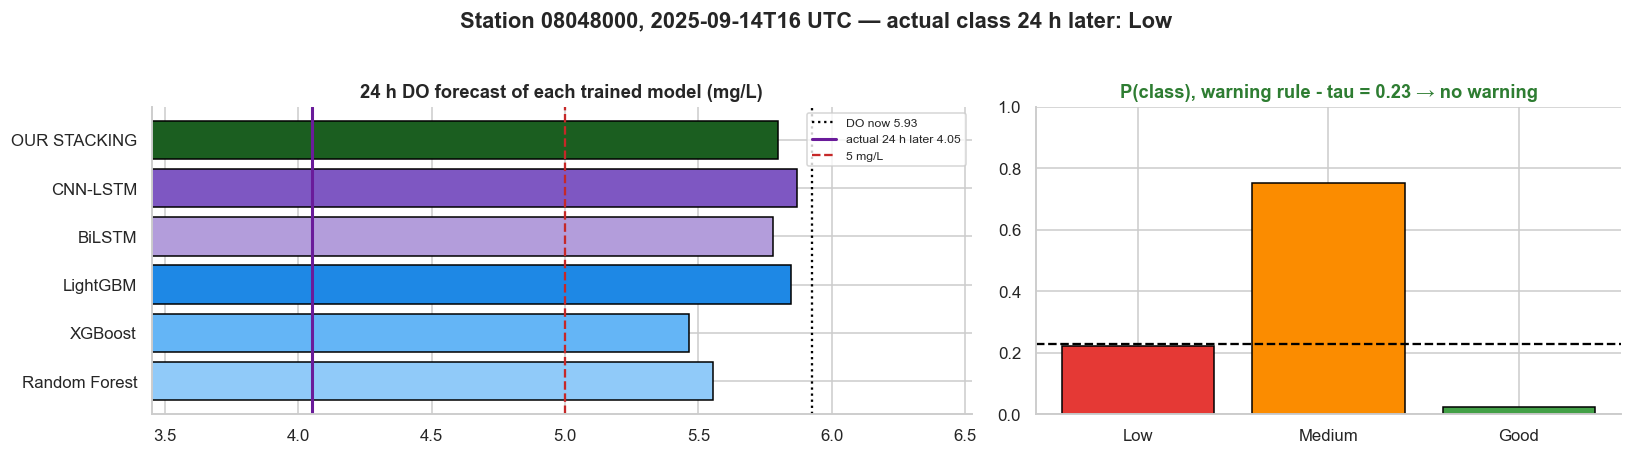

In [19]:
# @title 12. Forecast one unseen hour with all trained models
case = "safe now, Low in 24 h"  # @param ["safe now, Low in 24 h", "healthy river", "random hour"]
d = SPLITS["test"]; yr = d["y"][:, col[f"y_reg_{H}"]]; yc = d["y"][:, col[f"y_cls_{H}"]]
mask = {"safe now, Low in 24 h": (d["class_now"] != 0) & (yc == 0), "healthy river": (d["class_now"] == 2) & (yc == 2),
        "random hour": ~np.isnan(yc)}[case] & ~np.isnan(PRED["stacking"]["test_proba"]).any(1)
i = int(np.random.default_rng(7).choice(np.flatnonzero(mask)))
p = PRED["stacking"]["test_proba"][i]; warned = p[0] >= TAU
fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1.4, 1]})
vals = [PRED[m]["test_reg"][i] for m in MEMBERS] + [PRED["stacking"]["test_reg"][i]]
axes[0].barh([NICE[m] for m in MEMBERS] + ["OUR STACKING"], vals, color=["#90CAF9", "#64B5F6", "#1E88E5", "#B39DDB", "#7E57C2", "#1B5E20"], edgecolor="black")
axes[0].axvline(d["do_now"][i], color="black", ls=":", label=f"DO now {d['do_now'][i]:.2f}")
axes[0].axvline(yr[i], color="#6A1B9A", lw=2, label=f"actual 24 h later {yr[i]:.2f}"); axes[0].axvline(5, color="#C62828", ls="--", label="5 mg/L")
axes[0].set_xlim(min(vals + [yr[i], 5]) - .6, max(vals + [yr[i], d['do_now'][i]]) + .6); axes[0].legend(fontsize=8)
axes[0].set_title("24 h DO forecast of each trained model (mg/L)", fontweight="bold")
axes[1].bar(CLASSES, p, color=["#E53935", "#FB8C00", "#43A047"], edgecolor="black"); axes[1].axhline(TAU, color="black", ls="--")
axes[1].set_ylim(0, 1); axes[1].set_title(f"P(class), warning rule - tau = {TAU:.2f} → {'WARNING' if warned else 'no warning'}", fontweight="bold",
                                          color="#C62828" if warned else "#2E7D32")
plt.suptitle(f"Station {STATIONS[d['station'][i]]}, {str(d['time'][i])} UTC — actual class 24 h later: {CLASSES[int(yc[i])]}",
             fontweight="bold", y=1.03); plt.tight_layout(); plt.show()

---

## What This Notebook Establishes

1. **A leakage-free pipeline.** The chronological split is audited in Section 2 rather than asserted, and every
   imputer, scaler and class weight is fitted on 2023 alone.
2. **Five genuinely different learners.** Bagged trees, two boosting libraries with different split strategies,
   and two multi-task sequence networks trained on the GPU with mixed precision and early stopping on 2024.
3. **Two ensembles, each matched to its task.** Ridge stacking for the continuous target; Caruana greedy
   selection with replacement for the probability simplex, implemented inline in Section 8.2 and reproducing
   the project's `ensemble_v21`.
4. **One blind evaluation.** 2025 is read once, in Section 9, with five metrics per task and the plain argmax
   rule for classification.
5. **Honest scaling.** Section 10 puts the demo numbers next to the official full-dataset results from
   `results/test_v21/` and says plainly why they differ.

*The full comparison against published algorithms, at all four horizons, is in notebook
`01_DO_Algorithm_Comparison_Benchmark_Colab.ipynb`. The previous version of this notebook is kept at
`notebooks/archive/02_DO_End_to_End_Training_GPU_Colab_before_v21.ipynb`.*